# 02. Classical features: HOG, LBP and GLCM

Question: *how do gradient (HOG) and texture (LBP, GLCM) descriptors represent the six NEU defect
classes, and how separable are the classes in each feature space?*

All features are computed by the same code the classifiers use (`idefect.features`). Extractors are
stateless (no fitted parameters), so computing them for every image cannot leak information between
splits. Figures are produced by `scripts/classical_report.py`.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import Image, display

from idefect.config import load_config

cfg = load_config("configs/neu_baseline.yaml")
RES = Path(cfg.output.results_dir)
FIG = Path(cfg.output.figures_dir)


def show(path):
    # Display a saved figure at full resolution.
    display(Image(filename=str(path)))

from idefect.features.registry import extract_one
im = np.random.rand(cfg.data.image_size, cfg.data.image_size).astype(np.float32)
pd.DataFrame([{"descriptor": d.upper(), "dimension": extract_one(im, d, cfg).size}
              for d in ("hog", "lbp", "glcm")]).set_index("descriptor")

,dimension
descriptor,
HOG,1764
LBP,54
GLCM,48


## LBP: micro-texture codes

Each pixel becomes a rotation-invariant uniform pattern code (spot, edge, corner, flat area, or
non-uniform). The bottom panel is the mean code histogram per class at (P=8, R=1): the classes differ
mostly in how often edge-like codes (middle values) occur versus flat and non-uniform codes.

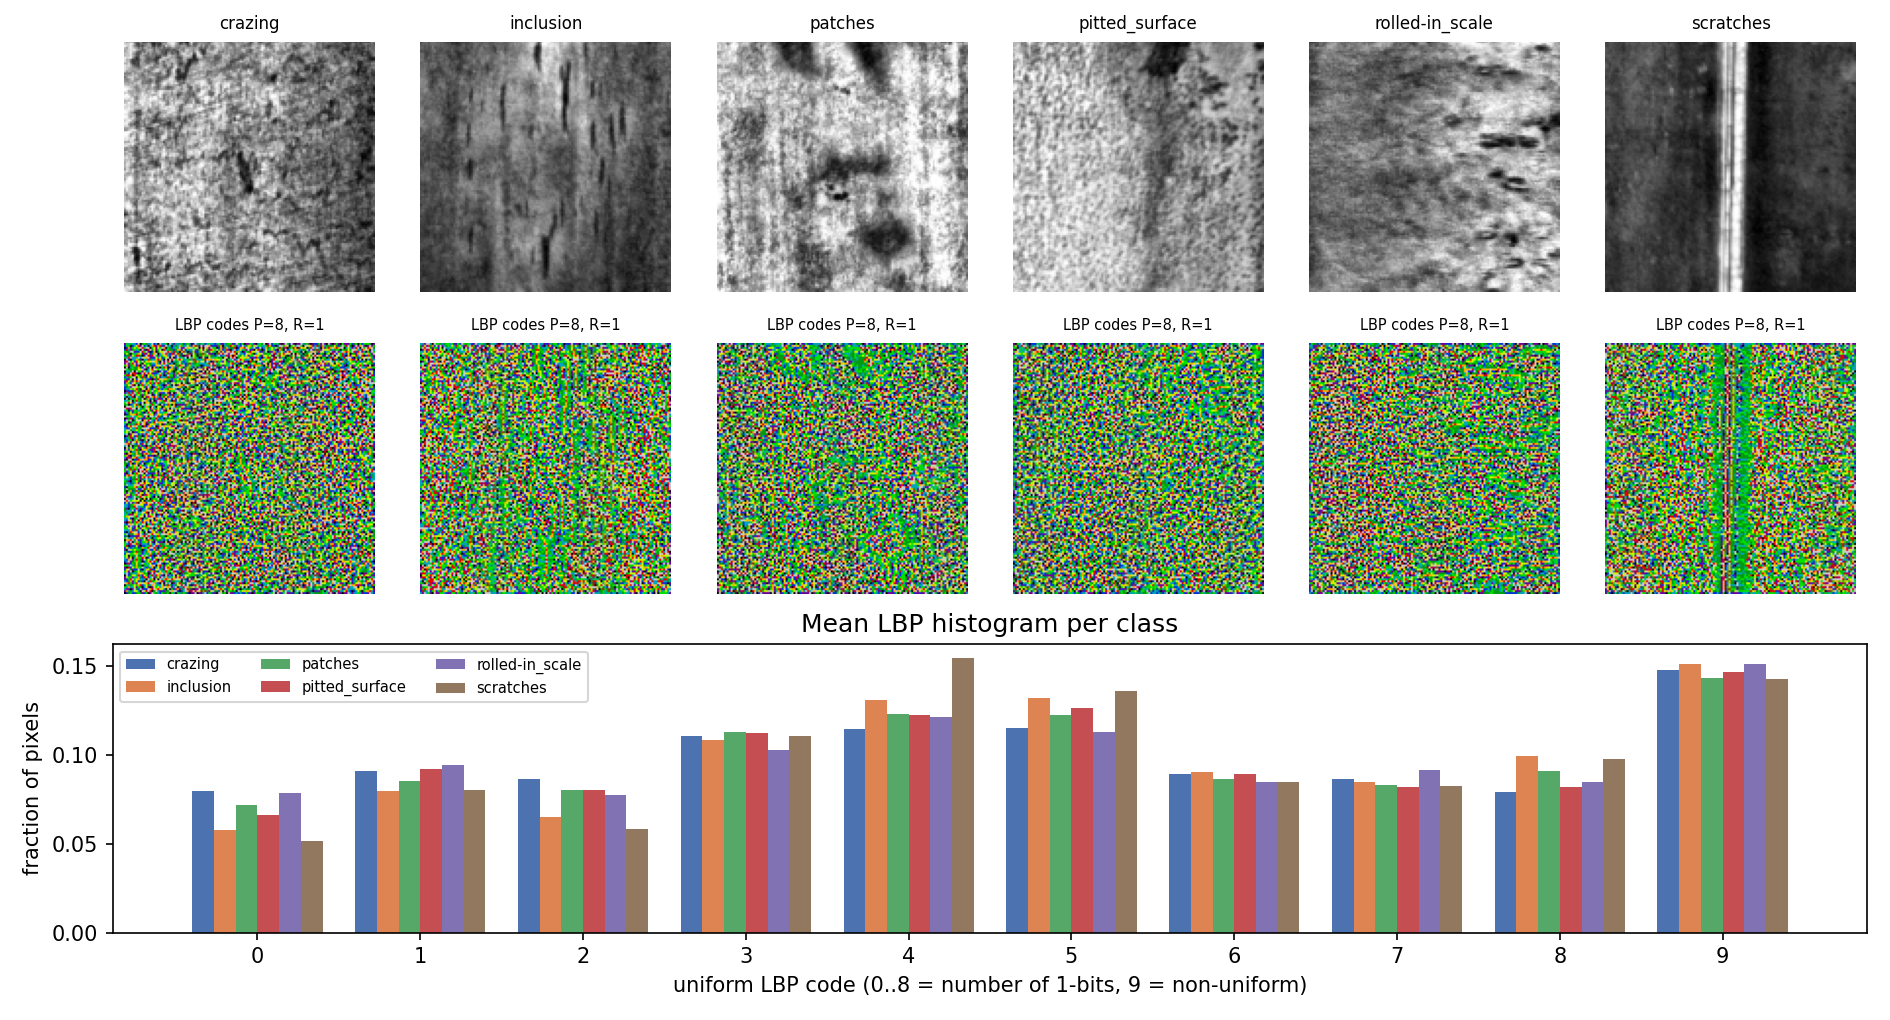

In [2]:
show(FIG / "classical" / "lbp_codes_and_histograms.png")

## GLCM: co-occurrence statistics

Contrast and dissimilarity grow with strong local grey-level changes (patches, crazing);
homogeneity, energy and ASM grow with smooth, uniform surfaces (inclusion, rolled-in scale);
correlation measures how linearly predictable neighbouring grey levels are.

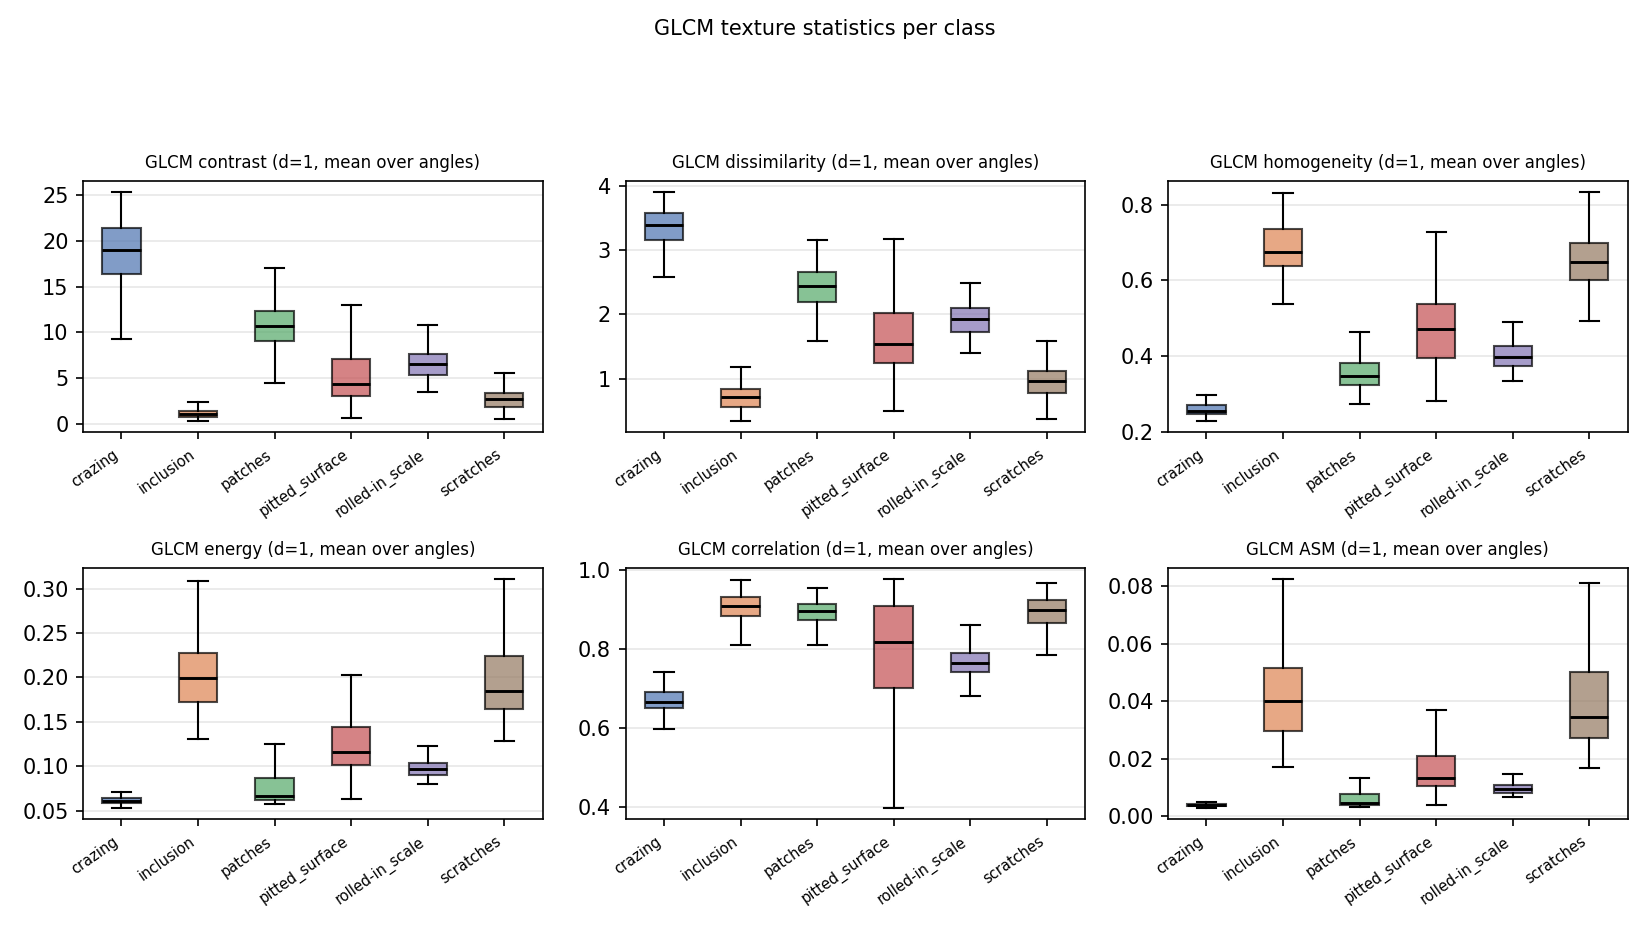

In [3]:
show(FIG / "classical" / "glcm_distributions.png")

## Feature-space projections

PCA shows the dominant linear structure; t-SNE shows local neighbourhoods. Classes that form
compact, separate clusters are easy for any classifier; overlapping clusters predict confusions.

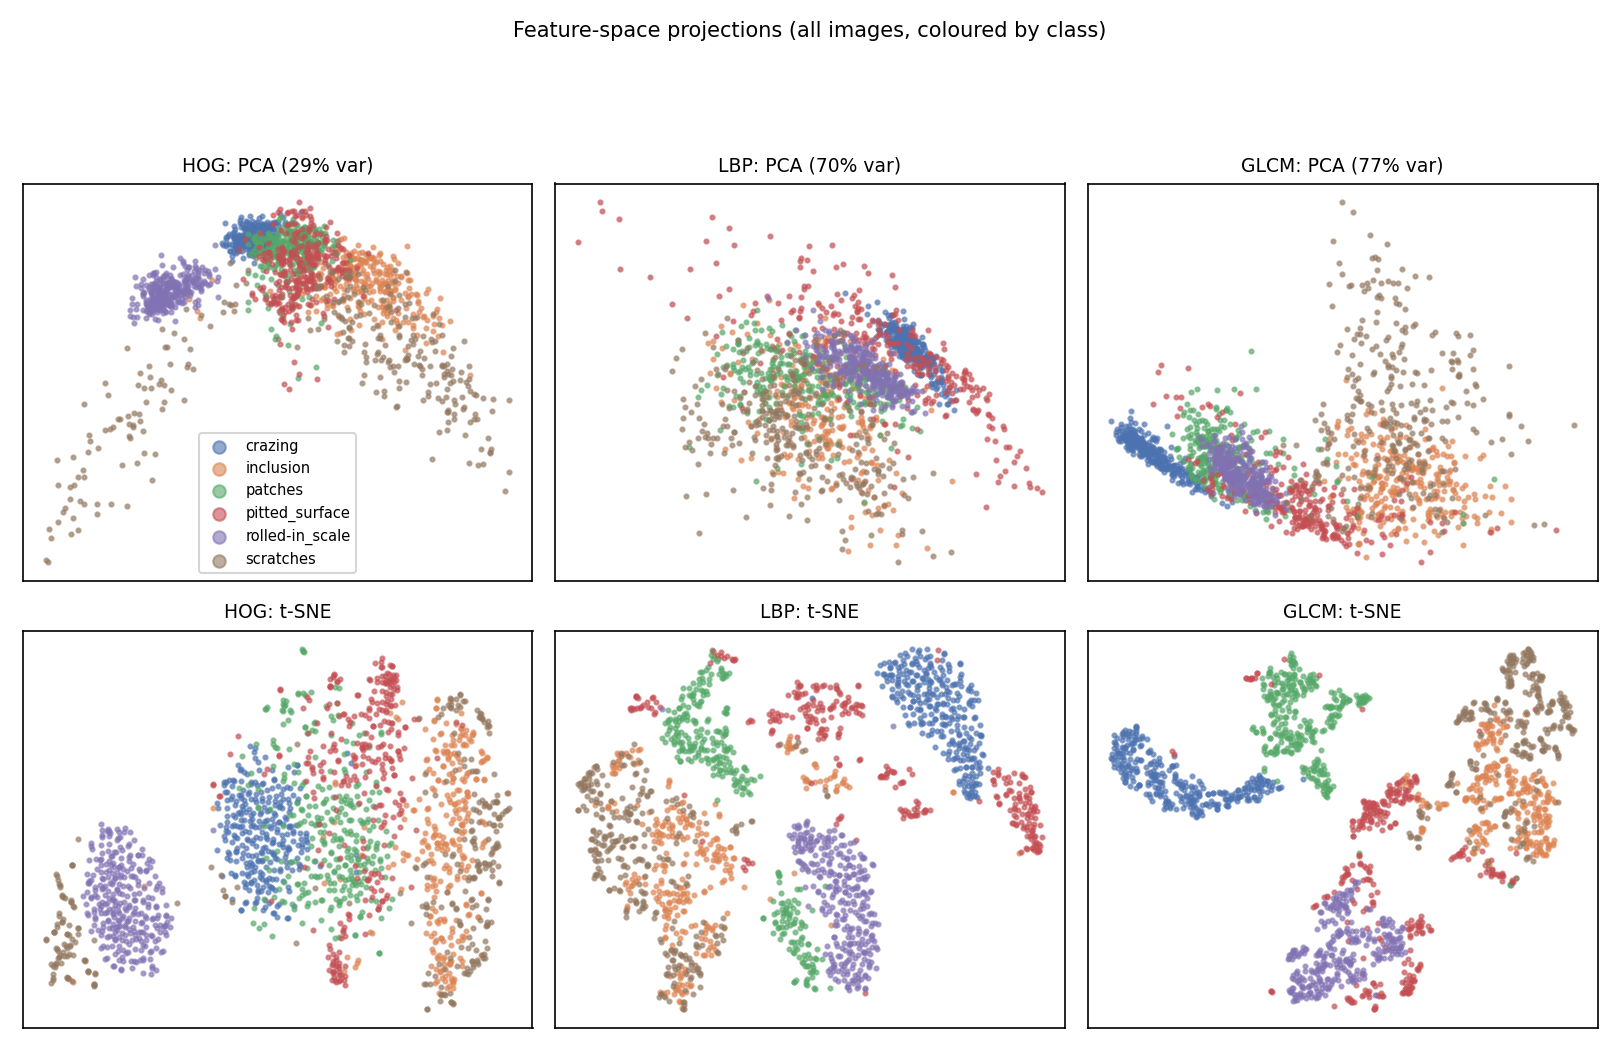

In [4]:
show(FIG / "classical" / "feature_projections.png")

In the t-SNE maps, LBP and GLCM form compact clusters for crazing, patches and rolled-in scale,
while inclusion and scratches overlap: both are elongated streaks on a smooth background. That overlap is
exactly where the classifiers make most of their mistakes (see notebook 03). HOG mixes crazing, patches and
pitted surface, consistent with its much lower scores.

## Descriptor comparison (cross-validation on the training split)

Mean macro-F1 of the best classifier for each feature set, from the grouped 5-fold search.

In [5]:
rows = json.loads((RES / "classical" / "grid.json").read_text())
df = pd.DataFrame(rows)
best = df.loc[df.groupby("feature_set")["cv_macro_f1_mean"].idxmax(),
              ["feature_set", "model", "feature_dim", "cv_macro_f1_mean", "cv_macro_f1_std"]]
best.sort_values("cv_macro_f1_mean", ascending=False).round(4)

,feature_set,model,feature_dim,cv_macro_f1_mean,cv_macro_f1_std
21,lbp+glcm,svm,102,0.9695,0.0233
15,glcm,svm,48,0.9527,0.0350
7,lbp,logreg,54,0.9453,0.0283
29,hog+lbp+glcm,xgboost,1866,0.9282,0.0307
3,hog,svm,1764,0.8275,0.0390


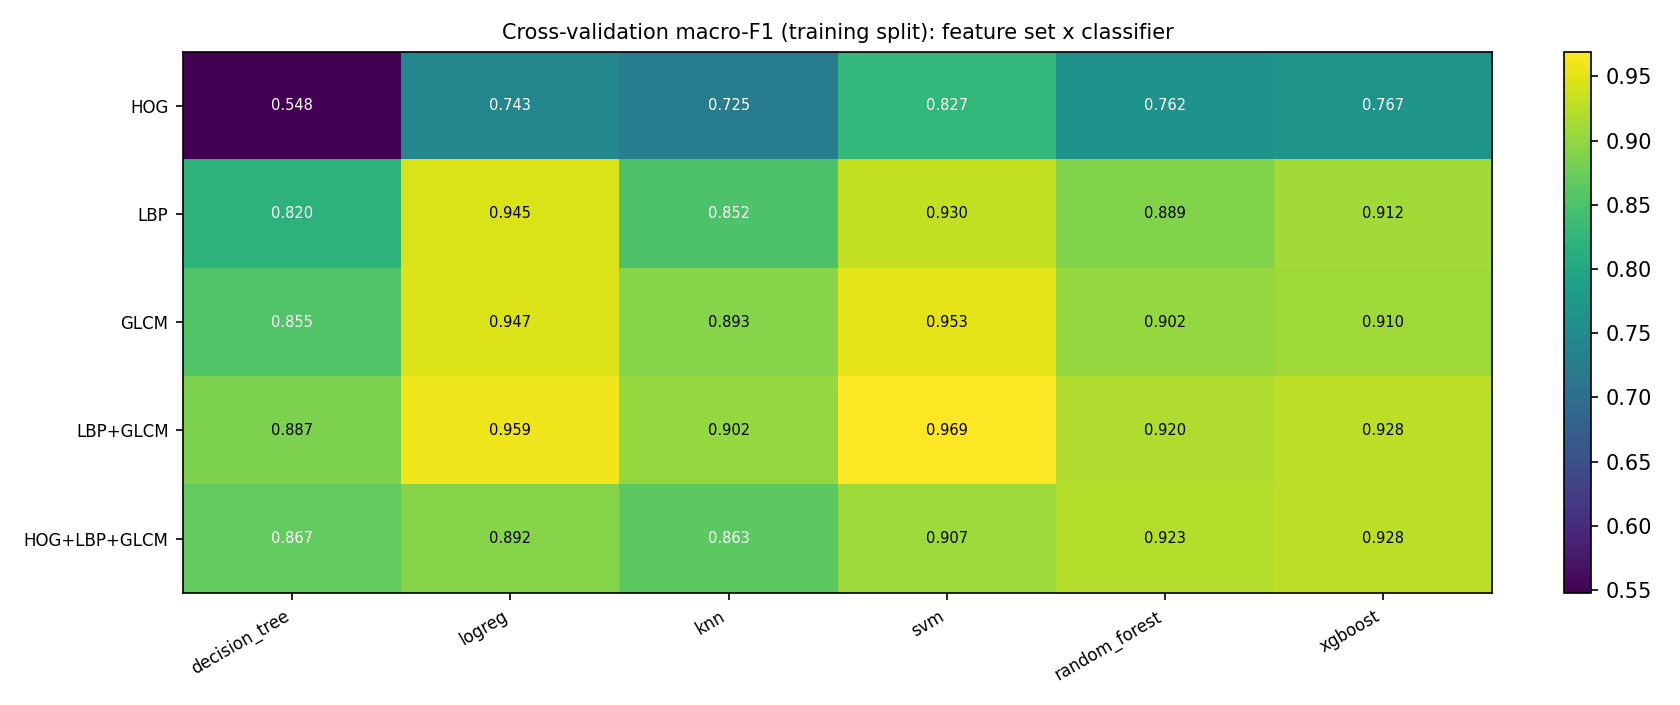

In [6]:
show(FIG / "classical" / "grid_cv_macro_f1.png")

Findings:

* **Texture beats gradients.** LBP (54 features) and GLCM (48 features) each reach about 0.95
  cross-validation macro-F1; HOG (1,764 features) tops out around 0.83 even with its best classifier.
* **LBP + GLCM is best (about 0.97 with an SVM).** The two descriptors are complementary: LBP captures
  local micro-patterns, GLCM captures grey-level co-occurrence statistics and directionality.
* **Adding HOG to LBP + GLCM hurts most classifiers** (SVM about 0.97 to 0.91, logistic regression about
  0.96 to 0.89): after standardization, 1,764 noisy gradient dimensions dominate distances and linear
  weights. Only the tree ensembles, which pick features per split, are unaffected.